# Task 1: Sales & Demand Forecasting for Businesses
**Future Interns - Machine Learning Track**

**Goal:** forecast the next 90 days of sales from 3 years of daily business data and explain the result in business terms.

**Workflow:** data cleaning -> time-based features -> model comparison -> error analysis -> 90-day forecast -> business insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.grid"] = True

## 1. Load data

In [2]:
df = pd.read_csv("data/sales_data.csv", parse_dates=["date"])
print(df.shape)
df.head()

(1102, 2)


,date,sales
0,2022-01-01,2240.33
1,2022-01-02,1977.99
2,2022-01-03,1690.58
3,2022-01-04,1764.67
4,2022-01-05,1555.69


## 2. Data cleaning
The raw file has duplicate rows, missing values and a few unrealistic spikes. All three are fixed below.

In [3]:
print("missing sales values :", df["sales"].isna().sum())
print("duplicate dates      :", df.duplicated(subset="date").sum())

df = df.drop_duplicates(subset="date").sort_values("date").set_index("date")
df = df.reindex(pd.date_range(df.index.min(), df.index.max(), freq="D"))
df.index.name = "date"

# fill gaps by interpolation
df["sales"] = df["sales"].interpolate()

# outliers: anything more than 2.5x the 7 day rolling median is treated as a data error
roll_med = df["sales"].rolling(7, center=True, min_periods=1).median()
mask = df["sales"] > 2.5 * roll_med
print("outlier spikes fixed :", mask.sum())
df.loc[mask, "sales"] = roll_med[mask]

print("clean rows           :", len(df), "| missing left:", df["sales"].isna().sum())

missing sales values : 12
duplicate dates      : 6
outlier spikes fixed : 5
clean rows           : 1096 | missing left: 0


## 3. Exploratory analysis

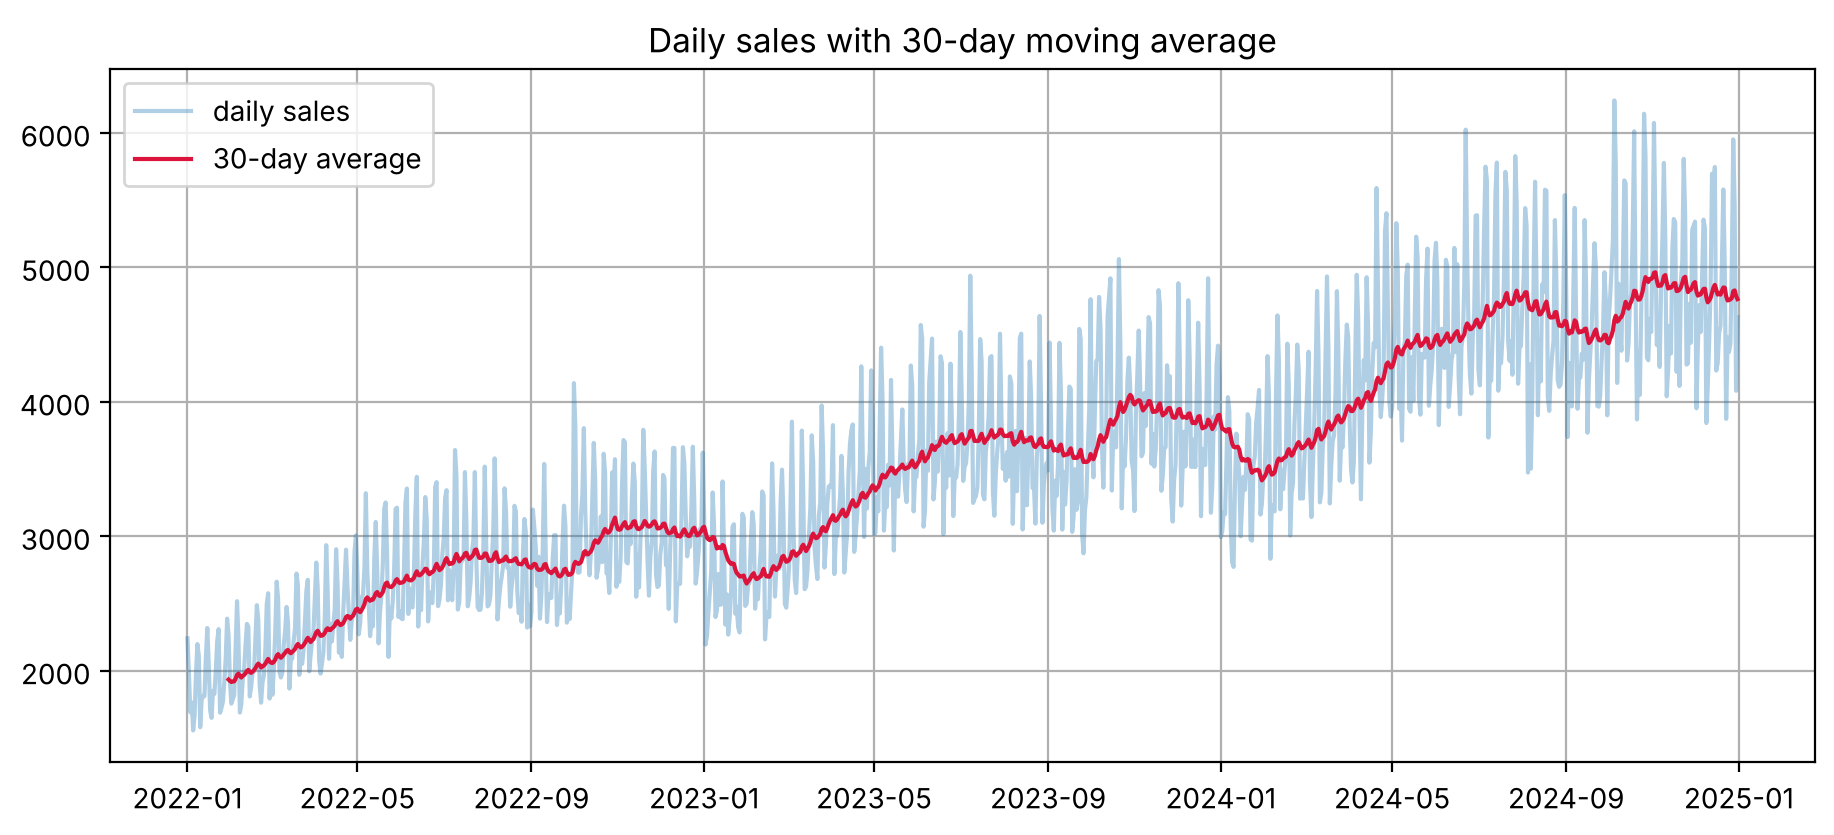

In [4]:
fig, ax = plt.subplots()
ax.plot(df.index, df["sales"], alpha=0.35, label="daily sales")
ax.plot(df.index, df["sales"].rolling(30).mean(), color="crimson", label="30-day average")
ax.set_title("Daily sales with 30-day moving average")
ax.legend()
plt.savefig("outputs/01_sales_trend.png", dpi=120, bbox_inches="tight")
plt.show()

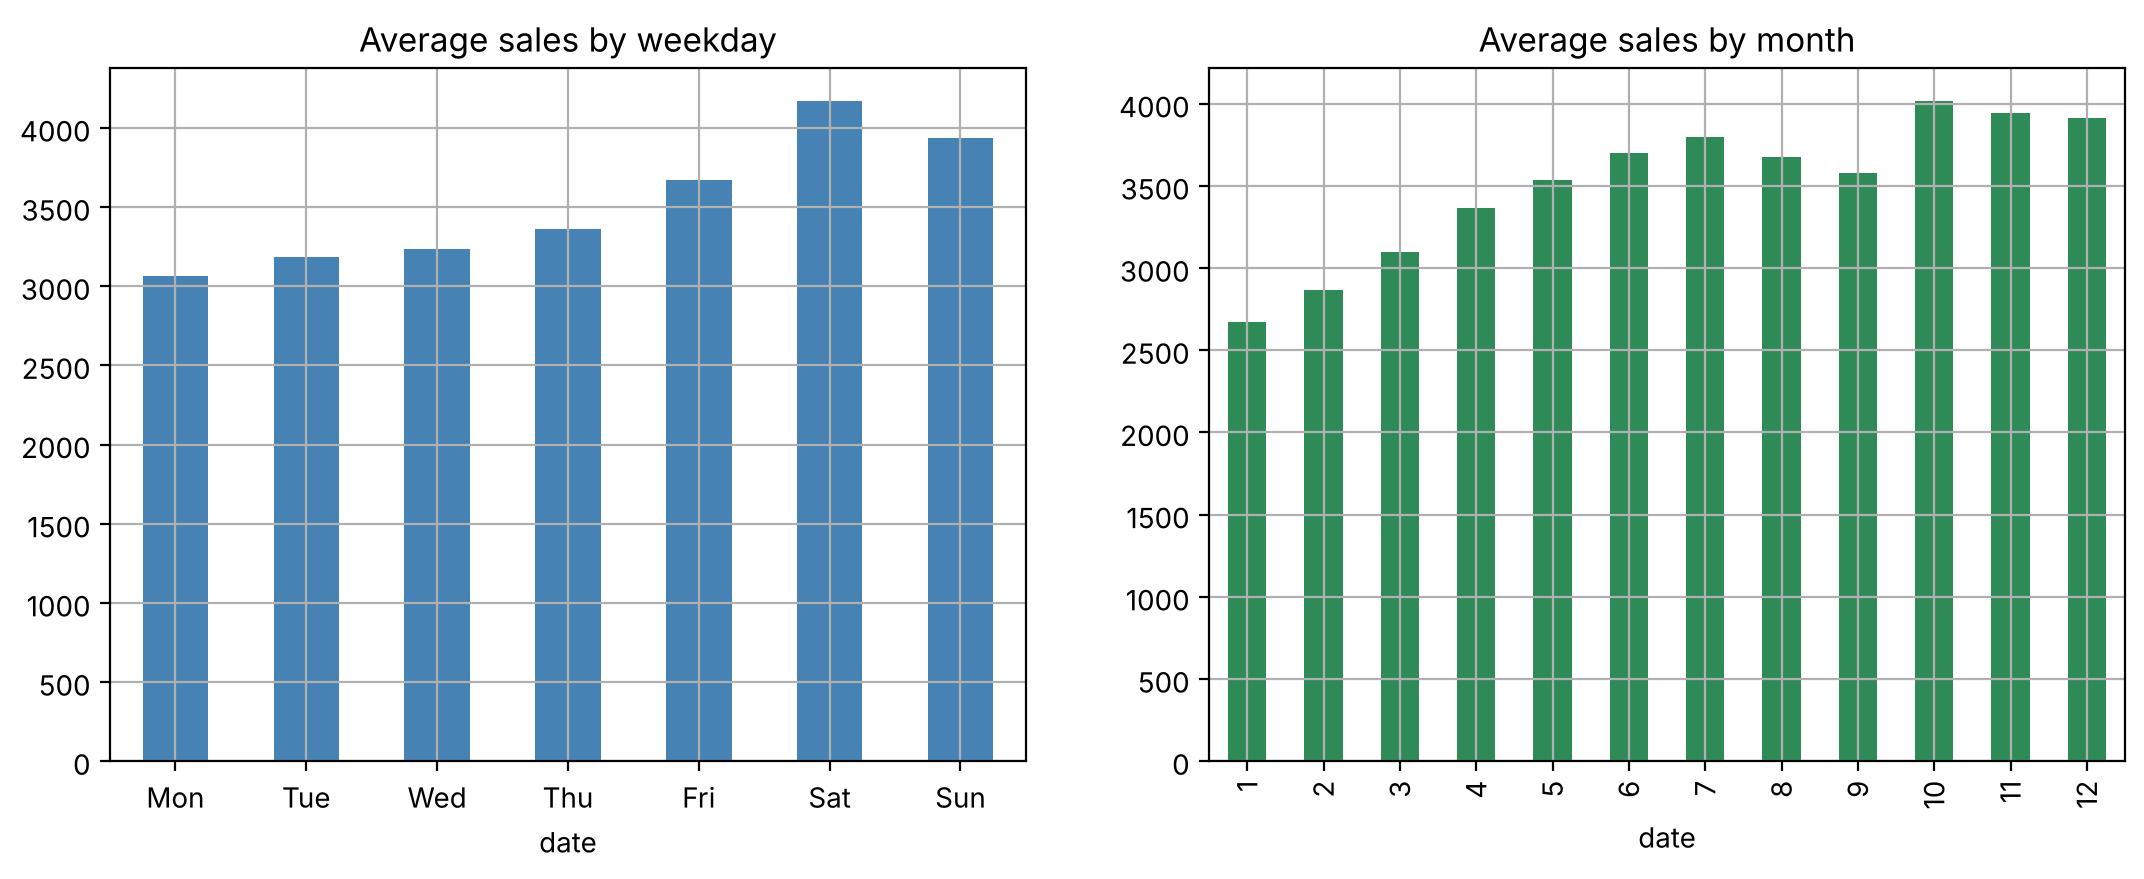

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
df.groupby(df.index.dayofweek)["sales"].mean().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], rotation=0)
axes[0].set_title("Average sales by weekday")
df.groupby(df.index.month)["sales"].mean().plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Average sales by month")
plt.savefig("outputs/02_seasonality.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Time-based feature engineering

In [6]:
START = df.index.min()

def make_features(idx):
    f = pd.DataFrame(index=idx)
    f["t"] = (idx - START).days
    f["month"] = idx.month
    f["dow"] = idx.dayofweek
    f["doy"] = idx.dayofyear
    f["week"] = idx.isocalendar().week.astype(int).values
    f["is_weekend"] = (f["dow"] >= 5).astype(int)
    f["is_month_end"] = idx.is_month_end.astype(int)
    f["sin_year"] = np.sin(2 * np.pi * f["doy"] / 365.25)
    f["cos_year"] = np.cos(2 * np.pi * f["doy"] / 365.25)
    return f

X_all = make_features(df.index)
y_all = df["sales"]

TEST_DAYS = 90
X_train, X_test = X_all.iloc[:-TEST_DAYS], X_all.iloc[-TEST_DAYS:]
y_train, y_test = y_all.iloc[:-TEST_DAYS], y_all.iloc[-TEST_DAYS:]
print("train:", X_train.index.min().date(), "->", X_train.index.max().date())
print("test :", X_test.index.min().date(), "->", X_test.index.max().date())
X_all.head()

train: 2022-01-01 -> 2024-10-02
test : 2024-10-03 -> 2024-12-31


,t,month,dow,doy,week,is_weekend,is_month_end,sin_year,cos_year
date,,,,,,,,,
2022-01-01,0,1,5,1,52,1,0,0.017202,0.999852
2022-01-02,1,1,6,2,52,1,0,0.034398,0.999408
2022-01-03,2,1,0,3,1,0,0,0.051584,0.998669
2022-01-04,3,1,1,4,1,0,0,0.068755,0.997634
2022-01-05,4,1,2,5,1,0,0,0.085906,0.996303


## 5. Models
Time series must be split **by time** (no random shuffle), so the last 90 days are held out as the test set.

| Model | Idea |
|---|---|
| Seasonal naive | baseline: repeat the last 7 days |
| Linear Regression | trend + weekday/month dummies |
| Trend + Random Forest | linear trend, forest learns the seasonal residual |
| Trend + Gradient Boosting | same idea with boosting |

Tree models cannot extrapolate a trend by themselves, so they are paired with a linear trend component.

In [7]:
def lin_matrix(X, cols=None):
    M = pd.get_dummies(X[["t", "sin_year", "cos_year", "is_weekend", "month", "dow"]],
                       columns=["month", "dow"], drop_first=True).astype(float)
    return M if cols is None else M.reindex(columns=cols, fill_value=0.0)

tree_cols = ["month", "dow", "doy", "week", "is_weekend", "is_month_end", "sin_year", "cos_year"]

def fit_predict(name, Xtr, ytr, Xte):
    if name == "Seasonal naive":
        last_week = ytr.iloc[-7:].values
        return np.resize(last_week, len(Xte))
    if name == "Linear Regression":
        Mtr = lin_matrix(Xtr)
        m = LinearRegression().fit(Mtr, ytr)
        return m.predict(lin_matrix(Xte, Mtr.columns))
    trend = LinearRegression().fit(Xtr[["t"]], ytr)
    resid = ytr - trend.predict(Xtr[["t"]])
    if name == "Trend + Random Forest":
        m = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)
    else:
        m = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
    m.fit(Xtr[tree_cols], resid)
    return trend.predict(Xte[["t"]]) + m.predict(Xte[tree_cols])

def scores(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

model_names = ["Seasonal naive", "Linear Regression", "Trend + Random Forest", "Trend + Gradient Boosting"]
preds, rows = {}, []
for n in model_names:
    preds[n] = fit_predict(n, X_train, y_train, X_test)
    mae, rmse, mape = scores(y_test.values, preds[n])
    rows.append([n, mae, rmse, mape])

results = pd.DataFrame(rows, columns=["model", "MAE", "RMSE", "MAPE %"]).set_index("model").round(2)
results.sort_values("RMSE")

,MAE,RMSE,MAPE %
model,,,
Trend + Gradient Boosting,223.78,287.52,4.64
Trend + Random Forest,226.54,295.04,4.70
Linear Regression,276.49,357.19,5.52
Seasonal naive,454.41,547.66,8.91


Best model on the 90-day test set: Trend + Gradient Boosting


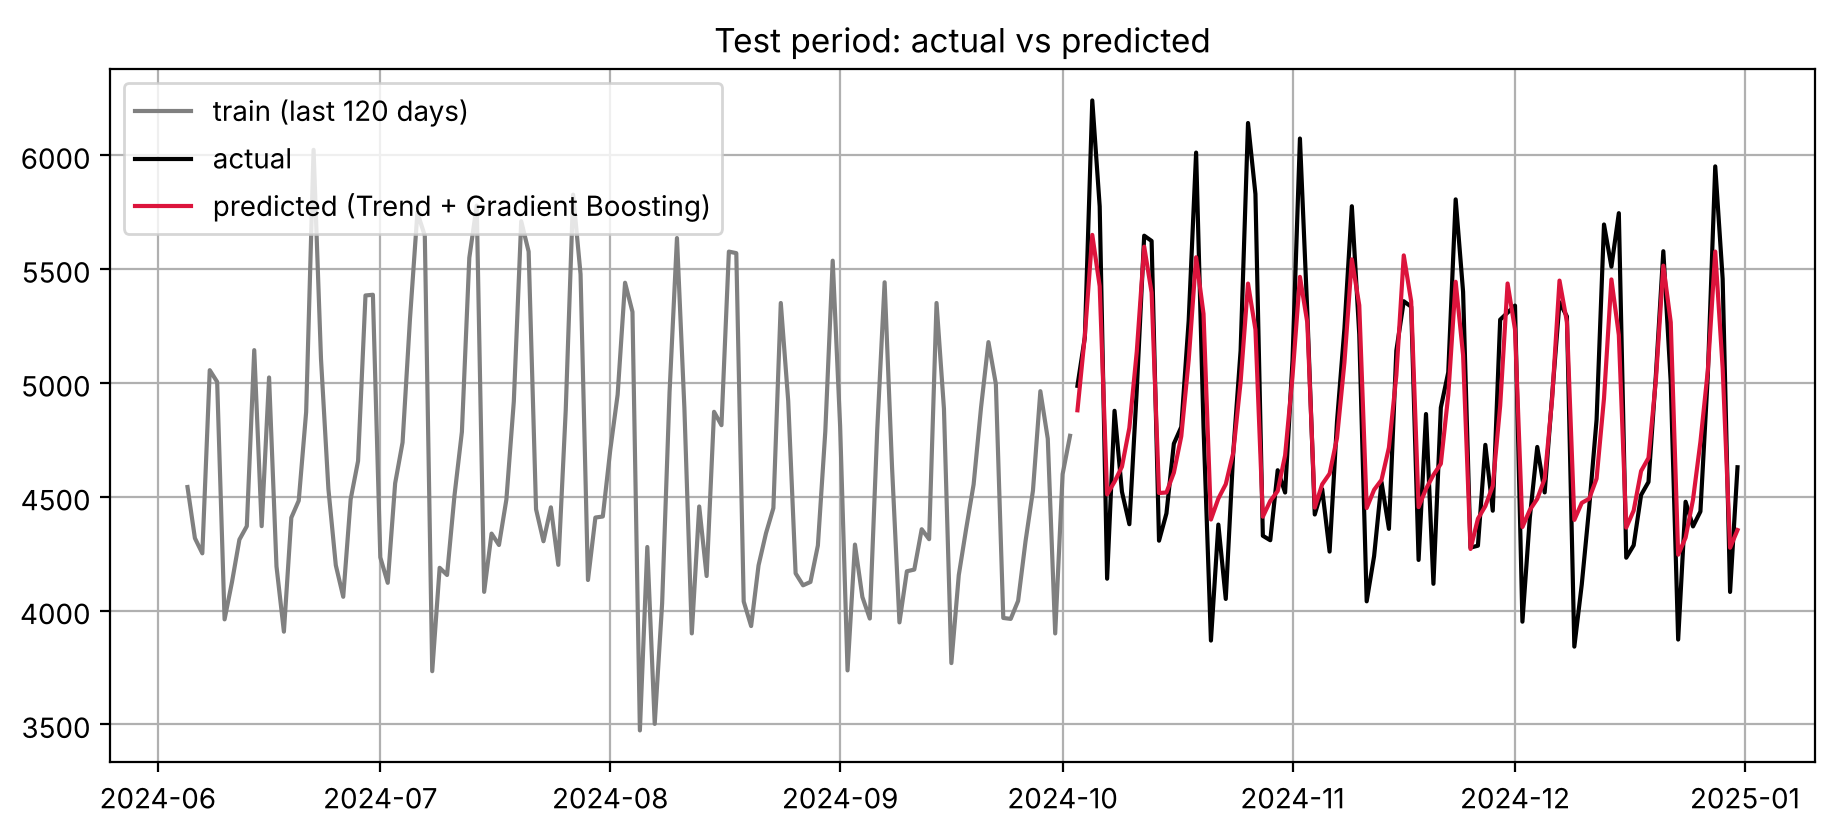

In [8]:
best = results["RMSE"].idxmin()
print("Best model on the 90-day test set:", best)

fig, ax = plt.subplots()
ax.plot(y_train.index[-120:], y_train.iloc[-120:], color="grey", label="train (last 120 days)")
ax.plot(y_test.index, y_test, color="black", label="actual")
ax.plot(y_test.index, preds[best], color="crimson", label=f"predicted ({best})")
ax.set_title("Test period: actual vs predicted")
ax.legend()
plt.savefig("outputs/03_test_predictions.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Error analysis

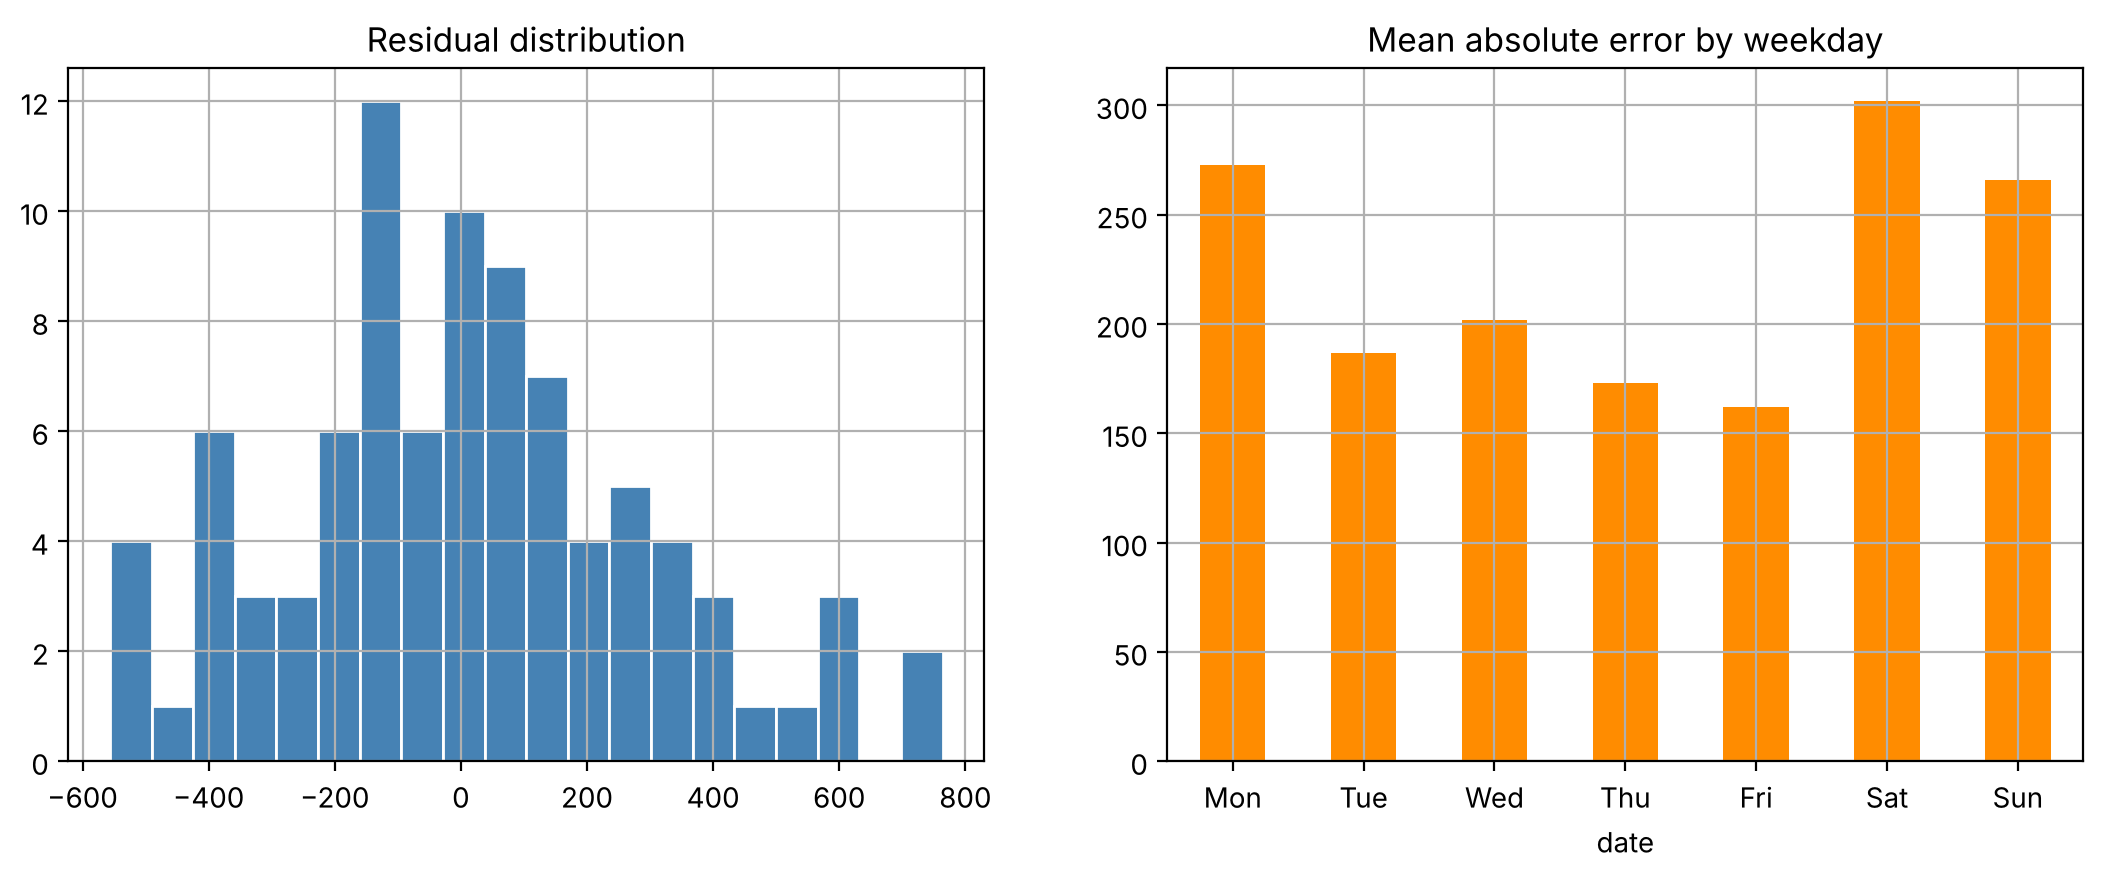

mean error (bias): 9.23
worst day        : 2024-12-13 | error: 763.83


In [9]:
err = pd.Series(y_test.values - preds[best], index=y_test.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(err, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Residual distribution")
err.groupby(err.index.dayofweek).apply(lambda s: s.abs().mean()).plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], rotation=0)
axes[1].set_title("Mean absolute error by weekday")
plt.savefig("outputs/04_error_analysis.png", dpi=120, bbox_inches="tight")
plt.show()

print("mean error (bias):", round(err.mean(), 2))
print("worst day        :", err.abs().idxmax().date(), "| error:", round(err.abs().max(), 2))

## 7. Final forecast (next 90 days)
The best model is re-trained on **all** the data and used to forecast beyond the last date. The shaded band is a rough 95% range based on test-set errors.

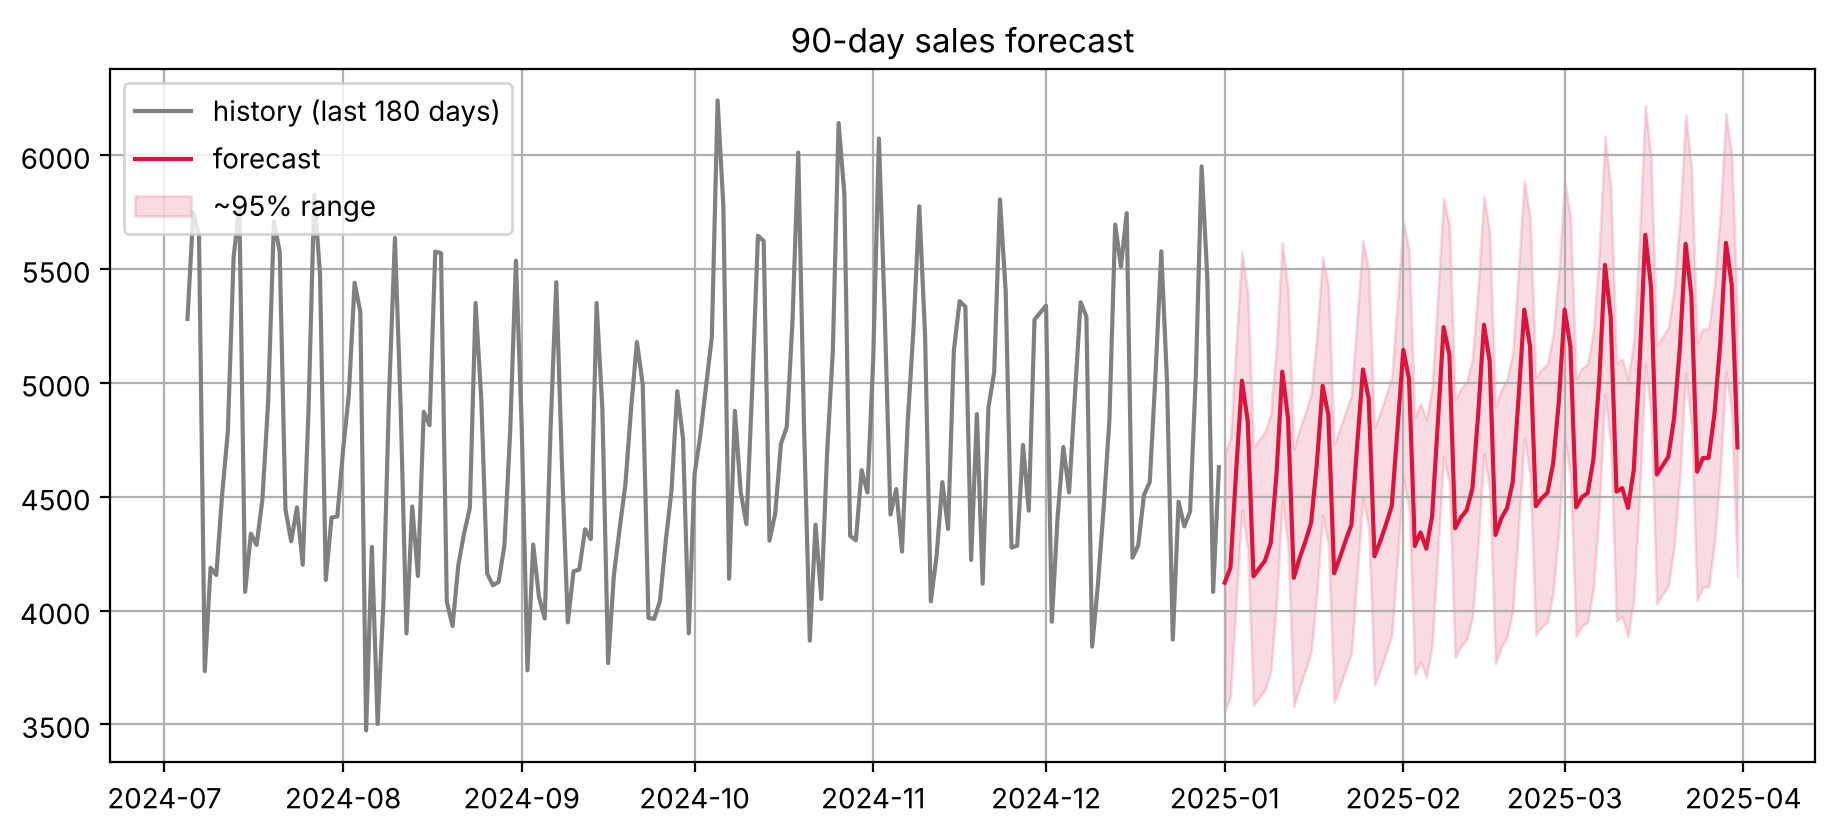

,date,forecast,lower,upper
0,2025-01-01,4122.24,3555.83,4688.64
1,2025-01-02,4187.81,3621.41,4754.21
2,2025-01-03,4614.85,4048.45,5181.26
3,2025-01-04,5009.99,4443.59,5576.39
4,2025-01-05,4832.08,4265.68,5398.48


In [10]:
future_idx = pd.date_range(df.index.max() + pd.Timedelta(days=1), periods=90, freq="D")
X_future = make_features(future_idx)
fc = pd.Series(fit_predict(best, X_all, y_all, X_future), index=future_idx)
band = 1.96 * err.std()

fig, ax = plt.subplots()
ax.plot(df.index[-180:], df["sales"].iloc[-180:], color="grey", label="history (last 180 days)")
ax.plot(fc.index, fc, color="crimson", label="forecast")
ax.fill_between(fc.index, fc - band, fc + band, color="crimson", alpha=0.15, label="~95% range")
ax.set_title("90-day sales forecast")
ax.legend()
plt.savefig("outputs/05_forecast.png", dpi=120, bbox_inches="tight")
plt.show()

out = pd.DataFrame({"date": fc.index, "forecast": fc.values.round(2),
                    "lower": (fc - band).values.round(2), "upper": (fc + band).values.round(2)})
out.to_csv("outputs/forecast_next_90_days.csv", index=False)
out.head()

## 8. Business insights

In [11]:
last_90 = df["sales"].iloc[-90:].sum()
next_90 = fc.sum()
growth = (next_90 / last_90 - 1) * 100
best_day = df.groupby(df.index.dayofweek)["sales"].mean().idxmax()
day_names = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
peak_month = df.groupby(df.index.month)["sales"].mean().idxmax()

print(f"Expected sales for the next 90 days : {next_90:,.0f}")
print(f"Previous 90 days                    : {last_90:,.0f}  ({growth:+.1f}% change)")
print(f"Strongest weekday                   : {day_names[best_day]}")
print(f"Strongest month (historically)      : {pd.Timestamp(2000, peak_month, 1).strftime('%B')}")
print(f"Model typical error                 : about {results.loc[best, 'MAPE %']:.1f}% per day")

Expected sales for the next 90 days : 424,839
Previous 90 days                    : 437,296  (-2.8% change)
Strongest weekday                   : Saturday
Strongest month (historically)      : October
Model typical error                 : about 4.6% per day


### Recommendations
- **Staffing & stock:** plan more inventory and staff for weekends, which are consistently the strongest days.
- **Festive quarter:** Oct-Dec runs well above the yearly trend, so stock-up decisions should be made before October.
- **Forecast confidence:** daily errors are small, but plan with the shaded range rather than the single line, especially for promotions or one-off events the model has not seen.
- **Next step:** add promotions, holidays and price as extra features once that data is available.